# CNOT Primitive XZ Stage 1
This file contains analysis for CNOT Primitive XZ stage-1 results (memory and single-gadget scans).

Stage 1 of `plans/xz_noise_hub_cnot.md`, simulated with `cnot_primitive_xz.jl` (local runs with a since-removed Julia runner, commit `86d161d`).

Noise model, per round: single-qubit depolarizing `p` (X, Y, Z each `p/3`) and measurement flips `q = p` on every X- and Z-type syndrome bit. At each CNOT: data noise, ideal transversal CNOT, two-qubit depolarizing `p2 = 10p` (each of the 15 non-identity Paulis `10p/15`), then the syndrome measurement. Decoder rule: primitive merge, mirrored per sector.

Per sector, the data flip rate is `2p/3`, so thresholds on this `p` axis are not directly comparable with the older X-only scans.

| Variant | Experiment |
| --- | --- |
| `memory_T1d`, `memory_T2d`, `memory_T4d` | One block, `T = d, 2d, 4d` noisy rounds, then ideal cleanup |
| `gadget_cnot_P2r10` | One noisy CNOT: `d` rounds, CNOT round, `d` rounds, both blocks read out (2408.01393-style gadget) |
| `gadget_idle_P2r10` | Same, gate replaced by an idle round that keeps the two-qubit noise |
| `gadget_cnot_P2r0` | Ideal gate: propagation and decoder merge, no two-qubit noise |
| `gadget_idle_P2r0` | Two independent memories of `2d+1` rounds |
| `gadget_cnot_P2r10_hubcontrol` | Gate direction reversed (symmetry check) |

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

PROJECT_DIR = next(
    (path for path in (Path.cwd(), Path.cwd().parent) if (path / "notebooks/analysis_utils.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Run this notebook from projects/mp-decoder or projects/mp-decoder/notebooks.")
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from analysis_utils import (
    P_MAX_BLOCK,
    display_finite_size_scaling_fit,
    display_fit_summary,
    fit_decay_rate,
    fit_finite_size_scaling,
    fit_lambda,
    lambda_ratios,
    load_ft_scan,
    plot_rate_scan,
)

DATA_ROOT = PROJECT_DIR / "results/cnot_primitive_xz/stage1"
L_VALUES = [5, 7, 9, 11, 13]
P_MEMORY = [round(0.008 + 0.002 * i, 3) for i in range(9)]
P_GATE_NOISY = [round(0.003 + 0.001 * i, 3) for i in range(11)]
P_GATE_IDEAL = P_MEMORY
COMPONENTS = {
    "hub X": "hub_x_failures",
    "hub Z": "hub_z_failures",
    "partner X": "partner_x_failures",
    "partner Z": "partner_z_failures",
}


def load_variant(name, p_values, failure_fields=None, L_values=L_VALUES):
    return load_ft_scan(
        DATA_ROOT / name,
        p_values=p_values,
        L_values=L_values,
        expected_repeats=1,
        result_pattern="2d_XZ_*.txt",
        success_field="Ft",
        failure_fields=failure_fields or {},
        scan_label=name,
    )


def plot_components(scan, title, tag):
    fig, axes = plt.subplots(2, 2, figsize=(10, 9), sharex=True, sharey=True)
    for ax, name in zip(axes.flat, COMPONENTS):
        est = scan.rate(name)
        for li, L in enumerate(scan.L_values):
            ax.errorbar(scan.p_values, est.values[li], yerr=est.errors[li], fmt="o-", capsize=2, label=f"L = {L}")
        ax.set_yscale("log")
        ax.set_title(f"{title} {name}: {tag}")
        ax.set_xlabel("p")
    axes[0, 0].set_ylabel("error_rate")
    axes[1, 0].set_ylabel("error_rate")
    axes[0, 0].legend()
    plt.show()

## 1. Memory reference: one block, `T = d` (Lake-style `p_log`)

Fixed aspect ratio `T = L`, as in Lake's numerics and the repository's baseline `Ft` mode. The finite-size crossing estimates the memory threshold under the new noise model.

Loaded 45 requested memory_T1d files; ignored 0 files outside the requested lists
L values: [ 5  7  9 11 13]
p values: [0.008 0.01  0.012 0.014 0.016 0.018 0.02  0.022 0.024]
repeat counts:
 [[1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]]


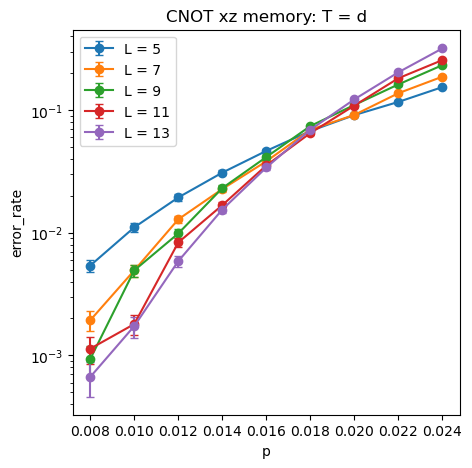

#### Finite-size scaling fit: XZ memory — T = d

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.014, 0.022]$ and $L \in [5, 7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.0177(1) |
| $p_c$ (%) | 1.77(1) |
| $\nu$ | 1.35(7) |
| $A$ | 0.062(2) |
| $B$ | 3.2(2) |
| $C$ | 54(8) |
| $\chi^2 / \mathrm{dof}$ | 54.32 / 20 = 2.72 |
| goodness-of-fit $p$-value | 5.19e-05 |

> **Fit-quality warning:** the degree-2 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

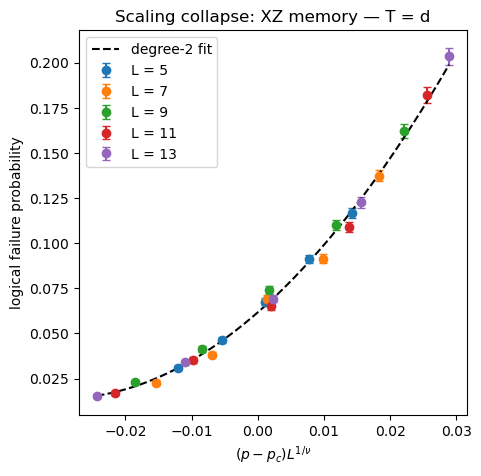

In [2]:
memory = load_variant("memory_T1d", P_MEMORY, {"X sector": "hub_x_failures", "Z sector": "hub_z_failures"})
memory.print_summary()
plot_rate_scan(memory, title="CNOT xz memory: T = d", ylabel="error_rate")
memory_fit = fit_finite_size_scaling(
    memory, label="XZ memory — T = d", fit_p_range=(0.014, 0.022), min_L=5, polynomial_degree=2
)
display_finite_size_scaling_fit(memory_fit, "logical failure probability")

## 2. Memory per-round error (Google-style) and suppression factor

For each `(L, p)`, fit `P(T) = P_max [1 - B (1 - eps/P_max)^T]` over `T = d, 2d, 4d` with `P_max = 15/16`. The intercept `B` absorbs the preparation and cleanup cost. `Lambda` comes from regressing `ln eps` on `(L+1)/2`, as in Google 2408.13687.

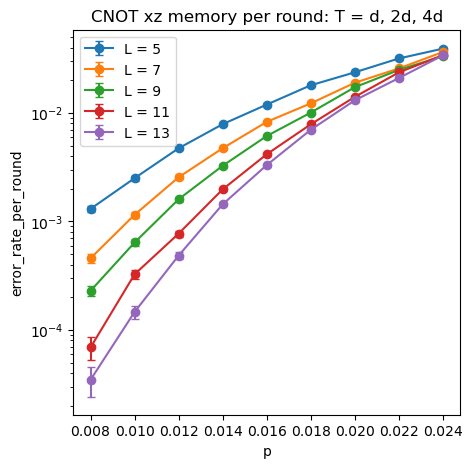

| p | Lambda (fit) | pairwise eps_L / eps_(L+2) |
| --- | --- | --- |
| 0.008 | 2.496 ± 0.120 | 5/7: 2.85±0.34, 7/9: 2.00±0.29, 9/11: 3.33±0.89, 11/13: 1.99±0.78 |
| 0.010 | 1.990 ± 0.051 | 5/7: 2.17±0.17, 7/9: 1.80±0.18, 9/11: 1.96±0.23, 11/13: 2.22±0.36 |
| 0.012 | 1.774 ± 0.030 | 5/7: 1.85±0.11, 7/9: 1.60±0.10, 9/11: 2.07±0.17, 11/13: 1.59±0.16 |
| 0.014 | 1.538 ± 0.018 | 5/7: 1.67±0.08, 7/9: 1.45±0.07, 9/11: 1.65±0.09, 11/13: 1.37±0.08 |
| 0.016 | 1.385 ± 0.014 | 5/7: 1.44±0.06, 7/9: 1.35±0.06, 9/11: 1.47±0.07, 11/13: 1.26±0.06 |
| 0.018 | 1.264 ± 0.012 | 5/7: 1.47±0.06, 7/9: 1.22±0.05, 9/11: 1.28±0.06, 11/13: 1.12±0.05 |
| 0.020 | 1.160 ± 0.011 | 5/7: 1.25±0.05, 7/9: 1.10±0.04, 9/11: 1.23±0.05, 11/13: 1.08±0.04 |
| 0.022 | 1.097 ± 0.010 | 5/7: 1.24±0.05, 7/9: 1.03±0.04, 9/11: 1.05±0.04, 11/13: 1.13±0.05 |
| 0.024 | 1.038 ± 0.011 | 5/7: 1.07±0.05, 7/9: 1.09±0.05, 9/11: 0.98±0.04, 11/13: 1.01±0.05 |

In [3]:
memory_T = {factor: load_variant(f"memory_T{factor}d", P_MEMORY) for factor in (1, 2, 4)}
eps_round = np.full((len(L_VALUES), len(P_MEMORY)), np.nan)
eps_round_err = np.full_like(eps_round, np.nan)
for li, L in enumerate(L_VALUES):
    for pj, p in enumerate(P_MEMORY):
        units, fails, trials = [], [], []
        for factor, scan in memory_T.items():
            t = scan.trials[li, pj]
            if t > 0:
                units.append(factor * L)
                fails.append(scan.rate().values[li, pj] * t)
                trials.append(t)
        try:
            fit = fit_decay_rate(units, fails, trials, p_max=P_MAX_BLOCK)
        except ValueError:
            continue
        eps_round[li, pj], eps_round_err[li, pj] = fit.eps, fit.eps_error

fig, ax = plt.subplots(figsize=(5, 5))
for li, L in enumerate(L_VALUES):
    ax.errorbar(P_MEMORY, eps_round[li], yerr=eps_round_err[li], fmt="o-", capsize=3, label=f"L = {L}")
ax.set_yscale("log")
ax.set_xlabel("p")
ax.set_ylabel("error_rate_per_round")
ax.set_title("CNOT xz memory per round: T = d, 2d, 4d")
ax.legend()
plt.show()

rows = ["| p | Lambda (fit) | pairwise eps_L / eps_(L+2) |", "| --- | --- | --- |"]
for pj, p in enumerate(P_MEMORY):
    try:
        lf = fit_lambda(L_VALUES, eps_round[:, pj], eps_round_err[:, pj])
    except ValueError:
        continue
    pairs = ", ".join(f"{a}/{b}: {r:.2f}±{e:.2f}" for a, b, r, e in lambda_ratios(L_VALUES, eps_round[:, pj], eps_round_err[:, pj]))
    rows.append(f"| {p:.3f} | {lf.Lambda:.3f} ± {lf.Lambda_error:.3f} | {pairs} |")
display(Markdown("\n".join(rows)))

## 3. One noisy CNOT gadget (`d` rounds, CNOT round, `d` rounds)

The failure probability of the whole gadget (any block, either sector) is the 2408.01393-style gate error. The hub (persistent block, here the target) absorbs the partner's X history; the partner absorbs the hub's Z history.

Loaded 55 requested gadget_cnot_P2r10 files; ignored 0 files outside the requested lists
L values: [ 5  7  9 11 13]
p values: [0.003 0.004 0.005 0.006 0.007 0.008 0.009 0.01  0.011 0.012 0.013]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]]


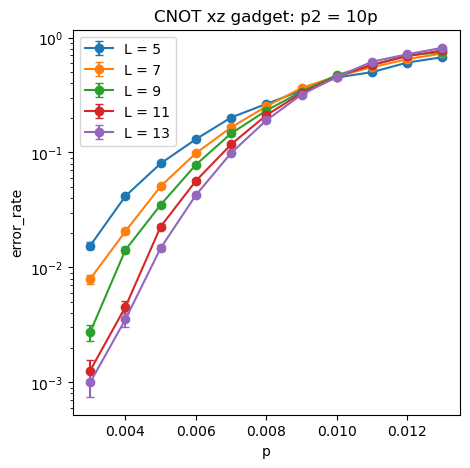

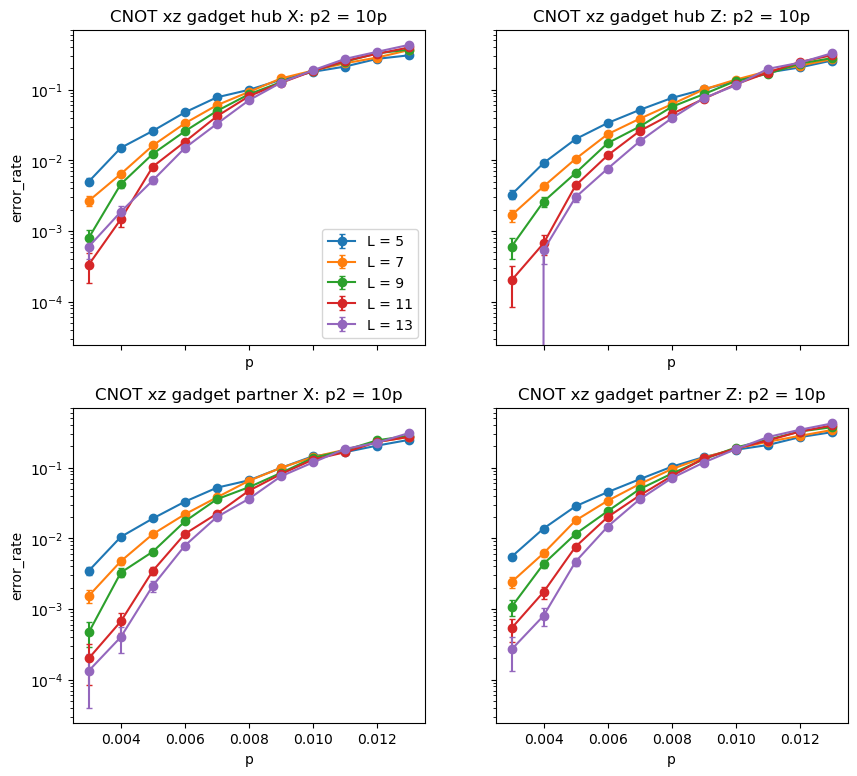

#### Finite-size scaling fit: XZ gadget — CNOT + two-qubit noise

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.007, 0.013]$ and $L \in [5, 7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.00966(9) |
| $p_c$ (%) | 0.966(9) |
| $\nu$ | 2.34(9) |
| $A$ | 0.410(9) |
| $B$ | 41(2) |
| $C$ | 134(48) |
| $\chi^2 / \mathrm{dof}$ | 142.23 / 30 = 4.74 |
| goodness-of-fit $p$-value | 1.57e-16 |

> **Fit-quality warning:** the degree-2 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

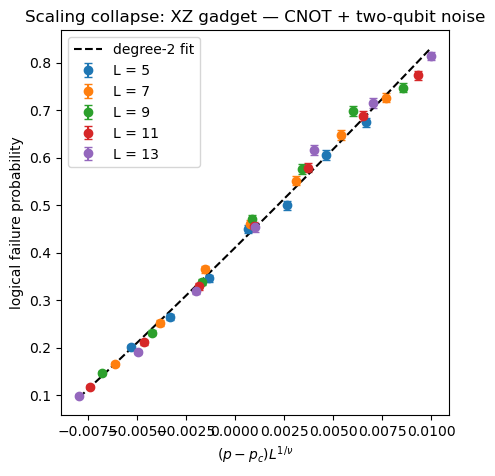

Gadget suppression factor (per gadget, including its `2d+1` rounds):

| p | Lambda (fit over L) | pairwise P_L / P_(L+2) |
| --- | --- | --- |
| 0.003 | 2.152 ± 0.100 | 5/7: 1.95±0.22, 7/9: 2.90±0.52, 9/11: 2.16±0.60, 11/13: 1.27±0.44 |
| 0.004 | 1.875 ± 0.047 | 5/7: 2.03±0.14, 7/9: 1.45±0.13, 9/11: 3.13±0.43, 11/13: 1.28±0.23 |
| 0.005 | 1.522 ± 0.021 | 5/7: 1.58±0.07, 7/9: 1.45±0.08, 9/11: 1.55±0.11, 11/13: 1.54±0.13 |
| 0.006 | 1.319 ± 0.013 | 5/7: 1.32±0.05, 7/9: 1.26±0.05, 9/11: 1.38±0.06, 11/13: 1.33±0.07 |
| 0.007 | 1.192 ± 0.009 | 5/7: 1.22±0.04, 7/9: 1.13±0.04, 9/11: 1.24±0.04, 11/13: 1.19±0.04 |
| 0.008 | 1.087 ± 0.008 | 5/7: 1.05±0.03, 7/9: 1.09±0.03, 9/11: 1.10±0.04, 11/13: 1.11±0.04 |
| 0.009 | 1.027 ± 0.007 | 5/7: 0.95±0.03, 7/9: 1.08±0.03, 9/11: 1.03±0.03, 11/13: 1.03±0.03 |
| 0.010 | 0.999 ± 0.006 | 5/7: 0.98±0.03, 7/9: 0.98±0.03, 9/11: 1.03±0.03, 11/13: 1.01±0.03 |
| 0.011 | 0.955 ± 0.005 | 5/7: 0.91±0.02, 7/9: 0.96±0.02, 9/11: 1.00±0.02, 11/13: 0.94±0.02 |
| 0.012 | 0.963 ± 0.005 | 5/7: 0.94±0.02, 7/9: 0.93±0.02, 9/11: 1.02±0.02, 11/13: 0.96±0.02 |
| 0.013 | 0.957 ± 0.004 | 5/7: 0.93±0.02, 7/9: 0.97±0.02, 9/11: 0.97±0.02, 11/13: 0.95±0.02 |

In [4]:
gadget = load_variant("gadget_cnot_P2r10", P_GATE_NOISY, COMPONENTS)
gadget.print_summary()
plot_rate_scan(gadget, title="CNOT xz gadget: p2 = 10p", ylabel="error_rate")
plot_components(gadget, "CNOT xz gadget", "p2 = 10p")
gadget_fit = fit_finite_size_scaling(
    gadget, label="XZ gadget — CNOT + two-qubit noise", fit_p_range=(0.007, 0.013), min_L=5, polynomial_degree=2
)
display_finite_size_scaling_fit(gadget_fit, "logical failure probability")

rows = ["| p | Lambda (fit over L) | pairwise P_L / P_(L+2) |", "| --- | --- | --- |"]
est = gadget.rate()
for pj, p in enumerate(P_GATE_NOISY):
    try:
        lf = fit_lambda(L_VALUES, est.values[:, pj], est.errors[:, pj])
    except ValueError:
        continue
    pairs = ", ".join(f"{a}/{b}: {r:.2f}±{e:.2f}" for a, b, r, e in lambda_ratios(L_VALUES, est.values[:, pj], est.errors[:, pj]))
    rows.append(f"| {p:.3f} | {lf.Lambda:.3f} ± {lf.Lambda_error:.3f} | {pairs} |")
display(Markdown("Gadget suppression factor (per gadget, including its `2d+1` rounds):\n\n" + "\n".join(rows)))

## 4. Ablations: what the gate costs

All four variants run the same `2d+1` rounds on two blocks; they differ only in what happens at the CNOT round.

## XZ stage-1 fit summary

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| XZ gadget — CNOT + two-qubit noise | 2 | 0.00966(9) | 0.966(9) | 2.34(9) | 4.74 | 1.57e-16 |
| XZ gadget — idle + two-qubit noise | 2 | 0.0105(1) | 1.05(1) | 2.34(9) | 4.98 | 8.29e-18 |
| XZ gadget — ideal CNOT | 2 | 0.0173(1) | 1.73(1) | 1.73(5) | 4.76 | 3.4e-14 |
| XZ gadget — two memories, 2d+1 rounds | 2 | 0.0180(1) | 1.80(1) | 1.49(5) | 2.56 | 0.000149 |
| XZ memory — T = d | 2 | 0.0177(1) | 1.77(1) | 1.35(7) | 2.72 | 5.19e-05 |

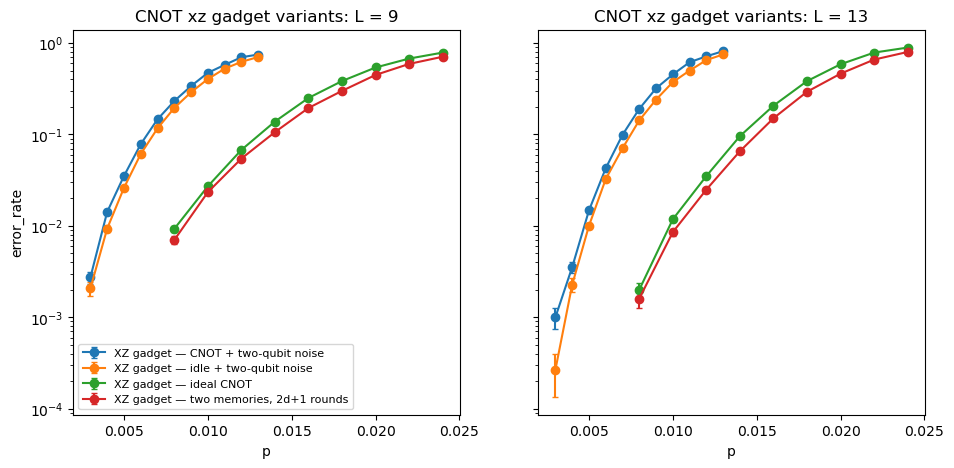

In [5]:
VARIANTS = {
    "gadget_cnot_P2r10": ("XZ gadget — CNOT + two-qubit noise", P_GATE_NOISY, (0.007, 0.013)),
    "gadget_idle_P2r10": ("XZ gadget — idle + two-qubit noise", P_GATE_NOISY, (0.007, 0.013)),
    "gadget_cnot_P2r0": ("XZ gadget — ideal CNOT", P_GATE_IDEAL, (0.012, 0.022)),
    "gadget_idle_P2r0": ("XZ gadget — two memories, 2d+1 rounds", P_GATE_IDEAL, (0.014, 0.022)),
}
variant_scans = {name: load_variant(name, ps) for name, (_, ps, _) in VARIANTS.items()}
variant_fits = []
for name, (label, ps, window) in VARIANTS.items():
    try:
        variant_fits.append(
            fit_finite_size_scaling(variant_scans[name], label=label, fit_p_range=window, min_L=5, polynomial_degree=2)
        )
    except Exception as err:  # keep going if one window is unusable
        print(f"{label}: fit failed ({err})")
display_fit_summary(variant_fits + [memory_fit], title="XZ stage-1 fit summary")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, L in zip(axes, (9, 13)):
    li = L_VALUES.index(L)
    for name, (label, _, _) in VARIANTS.items():
        scan = variant_scans[name]
        est = scan.rate()
        ax.errorbar(scan.p_values, est.values[li], yerr=est.errors[li], fmt="o-", capsize=2, label=label)
    ax.set_yscale("log")
    ax.set_xlabel("p")
    ax.set_title(f"CNOT xz gadget variants: L = {L}")
axes[0].set_ylabel("error_rate")
axes[0].legend(fontsize=8)
plt.show()

### 4b. Where the gate's cost lands

With the gate idle, all four sector failure rates are equal (the X↔Z symmetry). With the CNOT, the primitive rule makes two sectors absorb another block's history: the hub's X sector (the target absorbs the control's X history) and the partner's Z sector. Those two roughly double, while the source sectors (hub Z, partner X) match the idle case.

In [6]:
def sector_table(cnot_name, idle_name, p_values, L_values=(9, 13)):
    cnot_scan = load_variant(cnot_name, p_values, COMPONENTS, L_values=list(L_values))
    idle_scan = load_variant(idle_name, p_values, COMPONENTS, L_values=list(L_values))
    rows = ["| L | p | gate | hub X | hub Z | partner X | partner Z | any |", "| --- | --- | --- | --- | --- | --- | --- | --- |"]
    for li, L in enumerate(L_values):
        for pj, p in enumerate(p_values):
            for label, scan in (("cnot", cnot_scan), ("idle", idle_scan)):
                vals = [scan.rate(name).values[li, pj] for name in COMPONENTS] + [scan.rate().values[li, pj]]
                rows.append(f"| {L} | {p:.3f} | {label} | " + " | ".join(f"{v:.4f}" for v in vals) + " |")
    return "\n".join(rows)

display(Markdown("**With two-qubit gate noise (`p2 = 10p`)**\n\n" + sector_table("gadget_cnot_P2r10", "gadget_idle_P2r10", [0.006, 0.008])))
display(Markdown("**Without gate noise (`p2 = 0`)**\n\n" + sector_table("gadget_cnot_P2r0", "gadget_idle_P2r0", [0.012, 0.016])))

**With two-qubit gate noise (`p2 = 10p`)**

| L | p | gate | hub X | hub Z | partner X | partner Z | any |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 9 | 0.006 | cnot | 0.0257 | 0.0175 | 0.0173 | 0.0241 | 0.0782 |
| 9 | 0.006 | idle | 0.0158 | 0.0143 | 0.0167 | 0.0177 | 0.0610 |
| 9 | 0.008 | cnot | 0.0859 | 0.0570 | 0.0528 | 0.0820 | 0.2316 |
| 9 | 0.008 | idle | 0.0525 | 0.0546 | 0.0563 | 0.0606 | 0.1946 |
| 13 | 0.006 | cnot | 0.0149 | 0.0076 | 0.0079 | 0.0146 | 0.0426 |
| 13 | 0.006 | idle | 0.0089 | 0.0075 | 0.0083 | 0.0086 | 0.0325 |
| 13 | 0.008 | cnot | 0.0707 | 0.0392 | 0.0362 | 0.0708 | 0.1904 |
| 13 | 0.008 | idle | 0.0391 | 0.0410 | 0.0393 | 0.0387 | 0.1427 |

**Without gate noise (`p2 = 0`)**

| L | p | gate | hub X | hub Z | partner X | partner Z | any |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 9 | 0.012 | cnot | 0.0270 | 0.0138 | 0.0130 | 0.0242 | 0.0677 |
| 9 | 0.012 | idle | 0.0147 | 0.0146 | 0.0127 | 0.0134 | 0.0544 |
| 9 | 0.016 | cnot | 0.1045 | 0.0544 | 0.0499 | 0.1032 | 0.2505 |
| 9 | 0.016 | idle | 0.0520 | 0.0523 | 0.0507 | 0.0569 | 0.1946 |
| 13 | 0.012 | cnot | 0.0141 | 0.0069 | 0.0067 | 0.0125 | 0.0351 |
| 13 | 0.012 | idle | 0.0053 | 0.0062 | 0.0066 | 0.0071 | 0.0249 |
| 13 | 0.016 | cnot | 0.0843 | 0.0377 | 0.0396 | 0.0901 | 0.2062 |
| 13 | 0.016 | idle | 0.0418 | 0.0375 | 0.0397 | 0.0382 | 0.1502 |

## 5. Gate-direction symmetry check

Under the global X↔Z exchange (depolarizing noise, self-dual torus, identical decoders), reversing the gate direction should swap the sector labels: the default hub X equals the reversed hub Z, and so on. Each `z` is the difference in units of its binomial standard error.

In [7]:
sym_p = [0.006, 0.008, 0.010]
default = load_variant("gadget_cnot_P2r10", sym_p, COMPONENTS, L_values=[5, 9])
flipped = load_variant("gadget_cnot_P2r10_hubcontrol", sym_p, COMPONENTS, L_values=[5, 9])
pairs = [("hub X", "hub Z"), ("hub Z", "hub X"), ("partner X", "partner Z"), ("partner Z", "partner X")]
rows = ["| L | p | default | reversed | default rate | reversed rate | z |", "| --- | --- | --- | --- | --- | --- | --- |"]
for li, L in enumerate(default.L_values):
    for pj, p in enumerate(sym_p):
        for a, b in pairs:
            ra, ea = default.rate(a).values[li, pj], default.rate(a).errors[li, pj]
            rb, eb = flipped.rate(b).values[li, pj], flipped.rate(b).errors[li, pj]
            z = (ra - rb) / np.hypot(ea, eb)
            rows.append(f"| {L} | {p:.3f} | {a} | {b} | {ra:.4f} | {rb:.4f} | {z:+.2f} |")
display(Markdown("\n".join(rows)))

| L | p | default | reversed | default rate | reversed rate | z |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.006 | hub X | hub Z | 0.0477 | 0.0453 | +0.84 |
| 5 | 0.006 | hub Z | hub X | 0.0337 | 0.0325 | +0.49 |
| 5 | 0.006 | partner X | partner Z | 0.0330 | 0.0323 | +0.27 |
| 5 | 0.006 | partner Z | partner X | 0.0450 | 0.0484 | -1.23 |
| 5 | 0.008 | hub X | hub Z | 0.0993 | 0.1067 | -1.29 |
| 5 | 0.008 | hub Z | hub X | 0.0760 | 0.0763 | -0.06 |
| 5 | 0.008 | partner X | partner Z | 0.0661 | 0.0794 | -2.69 |
| 5 | 0.008 | partner Z | partner X | 0.1028 | 0.1014 | +0.24 |
| 5 | 0.010 | hub X | hub Z | 0.1787 | 0.1782 | +0.06 |
| 5 | 0.010 | hub Z | hub X | 0.1320 | 0.1463 | -1.70 |
| 5 | 0.010 | partner X | partner Z | 0.1452 | 0.1276 | +2.11 |
| 5 | 0.010 | partner Z | partner X | 0.1790 | 0.1720 | +0.75 |
| 9 | 0.006 | hub X | hub Z | 0.0257 | 0.0273 | -0.87 |
| 9 | 0.006 | hub Z | hub X | 0.0175 | 0.0168 | +0.46 |
| 9 | 0.006 | partner X | partner Z | 0.0173 | 0.0176 | -0.17 |
| 9 | 0.006 | partner Z | partner X | 0.0241 | 0.0277 | -1.93 |
| 9 | 0.008 | hub X | hub Z | 0.0859 | 0.0887 | -0.56 |
| 9 | 0.008 | hub Z | hub X | 0.0570 | 0.0554 | +0.39 |
| 9 | 0.008 | partner X | partner Z | 0.0528 | 0.0633 | -2.52 |
| 9 | 0.008 | partner Z | partner X | 0.0820 | 0.0825 | -0.10 |
| 9 | 0.010 | hub X | hub Z | 0.1857 | 0.1824 | +0.35 |
| 9 | 0.010 | hub Z | hub X | 0.1323 | 0.1343 | -0.24 |
| 9 | 0.010 | partner X | partner Z | 0.1370 | 0.1300 | +0.82 |
| 9 | 0.010 | partner Z | partner X | 0.1923 | 0.1885 | +0.39 |

High-statistics recheck (10^5 trials per configuration, `L = 5, 9`, `p = 0.008`, run separately): all eight comparisons agree within |z| < 1.8 (hub X 0.1049 vs reversed hub Z 0.1053 at `L = 5`; partner X 0.0554 vs reversed partner Z 0.0561 at `L = 9`). The two |z| ≈ 2.6 entries above at `p = 0.008` are fluctuations of the 1500-failure runs.

## 6. Cleanup failures

A cleanup failure means a block's buffers were not empty after `2d` ideal rounds; as in the legacy drivers, such trials are still read out and are not counted as logical failures by themselves.

In [8]:
import re
rows = ["| variant | trials | cleanup failures | fraction | worst point |", "| --- | --- | --- | --- | --- |"]
for variant_dir in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir()):
    total_t = total_c = 0
    worst = (0.0, "")
    for f in variant_dir.glob("2d_XZ_*.txt"):
        text = f.read_text()
        t = int(re.search(r"^trials = (\d+)", text, re.M).group(1))
        c = int(re.search(r"^cleanup_failures = (\d+)", text, re.M).group(1))
        L = int(float(re.search(r"^L = (\S+)", text, re.M).group(1)))
        p = float(re.search(r"^p = (\S+)", text, re.M).group(1))
        total_t += t
        total_c += c
        if t and c / t > worst[0]:
            worst = (c / t, f"L={L}, p={p}: {c}/{t}")
    rows.append(f"| {variant_dir.name} | {total_t} | {total_c} | {total_c / total_t:.1e} | {worst[1]} |")
display(Markdown("\n".join(rows)))

| variant | trials | cleanup failures | fraction | worst point |
| --- | --- | --- | --- | --- |
| gadget_cnot_P2r0 | 367873 | 382 | 1.0e-03 | L=9, p=0.022: 30/2221 |
| gadget_cnot_P2r10 | 456585 | 198 | 4.3e-04 | L=9, p=0.013: 16/2006 |
| gadget_cnot_P2r10_hubcontrol | 44793 | 49 | 1.1e-03 | L=9, p=0.01: 14/3268 |
| gadget_idle_P2r0 | 400749 | 372 | 9.3e-04 | L=9, p=0.024: 28/2121 |
| gadget_idle_P2r10 | 485985 | 163 | 3.4e-04 | L=9, p=0.013: 15/2138 |
| memory_T1d | 602645 | 475 | 7.9e-04 | L=9, p=0.024: 42/6439 |
| memory_T2d | 500403 | 294 | 5.9e-04 | L=9, p=0.024: 22/3488 |
| memory_T4d | 405220 | 212 | 5.2e-04 | L=9, p=0.022: 19/2679 |

## 7. Summary

In [9]:
lines = ["| Quantity | Estimate |", "| --- | --- |"]
for fit in [memory_fit] + variant_fits:
    pc, nu = fit.parameters[:2]
    epc, enu = fit.parameter_errors[:2]
    lines.append(f"| threshold, {fit.label} | p_c = {pc:.4f} ± {epc:.4f} (chi2/dof = {fit.chi2:.1f}/{fit.dof}) |")
display(Markdown("\n".join(lines)))

| Quantity | Estimate |
| --- | --- |
| threshold, XZ memory — T = d | p_c = 0.0177 ± 0.0001 (chi2/dof = 54.3/20) |
| threshold, XZ gadget — CNOT + two-qubit noise | p_c = 0.0097 ± 0.0001 (chi2/dof = 142.2/30) |
| threshold, XZ gadget — idle + two-qubit noise | p_c = 0.0105 ± 0.0001 (chi2/dof = 149.5/30) |
| threshold, XZ gadget — ideal CNOT | p_c = 0.0173 ± 0.0001 (chi2/dof = 118.9/25) |
| threshold, XZ gadget — two memories, 2d+1 rounds | p_c = 0.0180 ± 0.0001 (chi2/dof = 51.2/20) |